# Лабораторная работа №3: Foundation models для сегментации: SAM/SAM 2

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Получить маски по point и box prompts.
- Автоматически сформировать prompts из GT или детектора.
- Сравнить zero-shot и refinement head.


## Теоретическая часть

Promptable segmentation оценивает маску $M=f(I,p)$ по изображению и prompt $p$ (точка, box или маска). SAM разделяет тяжёлый image encoder и лёгкий prompt/mask decoder, поэтому один embedding изображения можно использовать для многих запросов.

![SAM architecture](https://raw.githubusercontent.com/facebookresearch/segment-anything/main/assets/model_diagram.png)


### Математическая постановка

Качество promptable-модели оценивают не только IoU, но и числом взаимодействий до достижения целевого качества: $N@IoU\geq\tau$. Для ускорения разметки важна доля масок, принимаемых без существенной коррекции.


### Материалы

- [Segment Anything](https://github.com/facebookresearch/segment-anything)
- [Transformers SAM docs](https://huggingface.co/docs/transformers/model_doc/sam)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Получить маски по point и box prompts.
2. Автоматически сформировать prompts из GT или детектора.
3. Сравнить zero-shot и refinement head.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** SAM ViT-B/MobileSAM inference, frozen encoder.
- **Ограничение данных:** до 200 изображений 512 px.
- **Fallback:** CPU на 20 изображениях или MobileSAM.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    # локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})

{'device': 'mps', 'fast_dev_run': False, 'data_root': '/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Загрузка SAM и отложенных масок

*Вес: 1 балл.*

**Постановка.** Сравнение prompts возможно лишь на одних размеченных изображениях.

Выполните следующие действия:
1. Загрузите pretrained SAM и test Oxford-IIIT Pet.
2. Зафиксируйте индексы проверки.

**Результат.** dataset_manifest.json и объекты processor, model, eval_ds.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
import torchvision
import transformers
from transformers import SamModel, SamProcessor
from PIL import Image

SAM_ID = "facebook/sam-vit-base"
MAX_SIDE = 512            # профиль работы: изображения не больше 512 px
N_EVAL = 20 if FAST_DEV_RUN else 200

processor = SamProcessor.from_pretrained(SAM_ID)
model = SamModel.from_pretrained(SAM_ID).to(DEVICE).eval()
for p in model.parameters():
    p.requires_grad = False

pets_test = torchvision.datasets.OxfordIIITPet(DATA_ROOT, split="test", target_types="segmentation", download=True)
pets_trainval = torchvision.datasets.OxfordIIITPet(DATA_ROOT, split="trainval", target_types="segmentation", download=True)

def load_item(dataset, i):
    """RGB и trimap, уменьшенные до MAX_SIDE по длинной стороне (маска — nearest)."""
    image, trimap = dataset[i]
    image = image.convert("RGB")
    scale = min(1.0, MAX_SIDE / max(image.size))
    if scale < 1:
        size = (round(image.width * scale), round(image.height * scale))
        image, trimap = image.resize(size, Image.BILINEAR), trimap.resize(size, Image.NEAREST)
    return image, np.array(trimap)

def has_object(dataset, i):
    """Есть ли в trimap животное (класс 1): без объекта нельзя получить ни точку, ни рамку."""
    return bool((np.array(Image.open(dataset._segs[i])) == 1).any())

test_with_object = np.array([i for i in range(len(pets_test)) if has_object(pets_test, i)])
eval_idx = np.sort(np.random.RandomState(SEED).choice(test_with_object, N_EVAL, replace=False))
eval_ds = [load_item(pets_test, int(i)) for i in eval_idx]
manifest = {"dataset": "Oxford-IIIT Pet (torchvision), split=test", "license": "CC BY-SA 4.0 (Oxford VGG)",
            "model": SAM_ID, "transformers": transformers.__version__, "max_side": MAX_SIDE, "seed": SEED,
            "eval_indices": eval_idx.tolist(),
            "gt_definition": "foreground = trimap 1; trimap 3 (граница) исключается из IoU; point и box строятся по trimap 1 (в части trimap класс 3 есть и у краёв кадра, рамка по 1∪3 тогда охватывает весь кадр)",
            "excluded_empty_test_masks": int(len(pets_test) - len(test_with_object))}
(ARTIFACTS / "dataset_manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
print(f"SAM: {SAM_ID}, параметров {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M; оценочных изображений {len(eval_ds)}; "
      f"test-изображений без животного в маске (исключены): {len(pets_test) - len(test_with_object)}")

SAM: facebook/sam-vit-base, параметров 93.7M; оценочных изображений 200; test-изображений без животного в маске (исключены): 7


### Геометрия подсказок и IoU

*Вес: 1 балл.*

**Постановка.** Box и point должны воспроизводимо извлекаться из одной истинной маски.

Выполните следующие действия:
1. Реализуйте IoU масок и ограничивающий прямоугольник.
2. Документируйте, что подсказки из GT моделируют действия разметчика.

**Результат.** Функции iou и box_from_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
def iou(pred, gt, valid=None):
    """IoU бинарных масок; valid — пиксели, участвующие в оценке (граница trimap исключается)."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    if valid is not None:
        pred, gt = pred & valid, gt & valid
    union = (pred | gt).sum()
    return float((pred & gt).sum() / union) if union else 1.0

def box_from_mask(mask):
    """[x0, y0, x1, y1] — ограничивающий прямоугольник ненулевых пикселей."""
    ys, xs = np.where(mask)
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

def median_point(mask):
    """Пиксель объекта, ближайший к покоординатной медиане (сама медиана может лежать вне объекта)."""
    ys, xs = np.where(mask)
    my, mx = np.median(ys), np.median(xs)
    k = np.argmin((ys - my) ** 2 + (xs - mx) ** 2)
    return [int(xs[k]), int(ys[k])]

def gt_masks(trimap):
    return trimap == 1, trimap != 3, trimap != 2   # foreground, valid-пиксели, объект вместе с границей

def inflated_union_box(trimap, ratio=1.5):
    """Рамка по классам 1∪3 больше рамки по классу 1 более чем в ratio раз (по площади) — признак полосы 3 у краёв кадра."""
    area = lambda b: (b[2] - b[0] + 1) * (b[3] - b[1] + 1)
    fg, _, obj = gt_masks(trimap)
    return area(box_from_mask(obj)) > ratio * area(box_from_mask(fg))

# Подсказки берутся из истинной разметки: так моделируются действия разметчика, который
# ставит точку на объект или обводит его рамкой. Это верхняя оценка качества для детектора-подсказчика.
# Рамка строится по классу 1 trimap: в части изображений класс 3 размечен и вдоль краёв кадра,
# и рамка по 1∪3 тогда охватывает весь кадр — такой подсказки разметчик не дал бы.
_m = np.zeros((10, 10), bool); _m[2:5, 3:8] = True
check(box_from_mask(_m) == [3, 2, 7, 4], "box_from_mask возвращает [x0, y0, x1, y1]")
check(iou(_m, _m) == 1.0 and iou(_m, ~_m) == 0.0, "IoU совпадающих масок = 1, непересекающихся = 0")
check(_m[median_point(_m)[1], median_point(_m)[0]], "медианная точка лежит на объекте")

✔ box_from_mask возвращает [x0, y0, x1, y1]
✔ IoU совпадающих масок = 1, непересекающихся = 0
✔ медианная точка лежит на объекте


### Предсказание SAM по подсказке

*Вес: 1 балл.*

**Постановка.** Encoder и mask decoder должны получать корректный тип prompt.

Выполните следующие действия:
1. Подайте point или box в processor.
2. Выберите маску по предсказанной SAM оценке IoU.

**Результат.** Функция predict_sam с бинарной маской исходного размера.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
@torch.no_grad()
def image_embedding(image):
    inputs = processor(images=image, return_tensors="pt").to(DEVICE)
    return model.get_image_embeddings(inputs["pixel_values"]), inputs

@torch.no_grad()
def sam_candidates(image, point=None, box=None, cache=None):
    """Логиты трёх multimask-кандидатов SAM в исходном размере и их предсказанные IoU."""
    emb, base = cache if cache is not None else image_embedding(image)
    kwargs = {}
    if point is not None:
        kwargs = dict(input_points=[[point]], input_labels=[[1]])
    if box is not None:
        kwargs = dict(input_boxes=[[box]])
    prompt = processor(images=image, return_tensors="pt", **kwargs)
    # процессор отдаёт координаты в float64, а MPS поддерживает только float32
    prompt = {k: (v.float() if v.is_floating_point() else v).to(DEVICE) for k, v in prompt.items() if k in ("input_points", "input_labels", "input_boxes")}
    out = model(image_embeddings=emb, multimask_output=True, **prompt)
    logits = processor.image_processor.post_process_masks(out.pred_masks.cpu(), base["original_sizes"].cpu(),
                                                          base["reshaped_input_sizes"].cpu(), binarize=False)[0][0]
    return logits.numpy(), out.iou_scores[0, 0].cpu().numpy()

def predict_sam(image, point=None, box=None, cache=None, return_logits=False):
    """Маска SAM исходного размера; из трёх multimask-кандидатов выбирается маска с max predicted IoU."""
    logits, scores = sam_candidates(image, point=point, box=box, cache=cache)
    best = int(scores.argmax())
    mask_logits, score = logits[best], float(scores[best])
    return (mask_logits > 0, score, mask_logits) if return_logits else (mask_logits > 0, score)

img0, tri0 = eval_ds[0]
fg0, valid0, obj0 = gt_masks(tri0)
mask0, score0 = predict_sam(img0, box=box_from_mask(fg0))
check(mask0.shape == tri0.shape, f"маска SAM имеет исходный размер {mask0.shape}")
print(f"пример: predicted IoU={score0:.3f}, IoU с GT={iou(mask0, fg0, valid0):.3f}")

✔ маска SAM имеет исходный размер (225, 300)
пример: predicted IoU=1.007, IoU с GT=0.999


### Сравнение point и box

*Вес: 1 балл.*

**Постановка.** Степень интерактивной подсказки влияет на качество сегментации.

Выполните следующие действия:
1. Получите две маски для каждого отложенного изображения.
2. Сохраните IoU, площади и координаты prompts.

**Результат.** prompt_results.json с реальными оценками SAM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
 "n": 200,
 "mean_point_iou": 0.8148691140915719,
 "mean_box_iou": 0.9668710880549953,
 "median_point_iou": 0.9886956456134804,
 "median_box_iou": 0.9942357363676674,
 "box_better_share": 0.63,
 "seconds_per_image_two_prompts": 0.7733617889881134,
 "n_union_box_inflated": 22,
 "point_best_candidate_mean_iou": 0.9583097285591166,
 "point_selection_matches_best_share": 0.625,
 "box_best_candidate_mean_iou": 0.9778834781497052,
 "box_selection_matches_best_share": 0.84
}


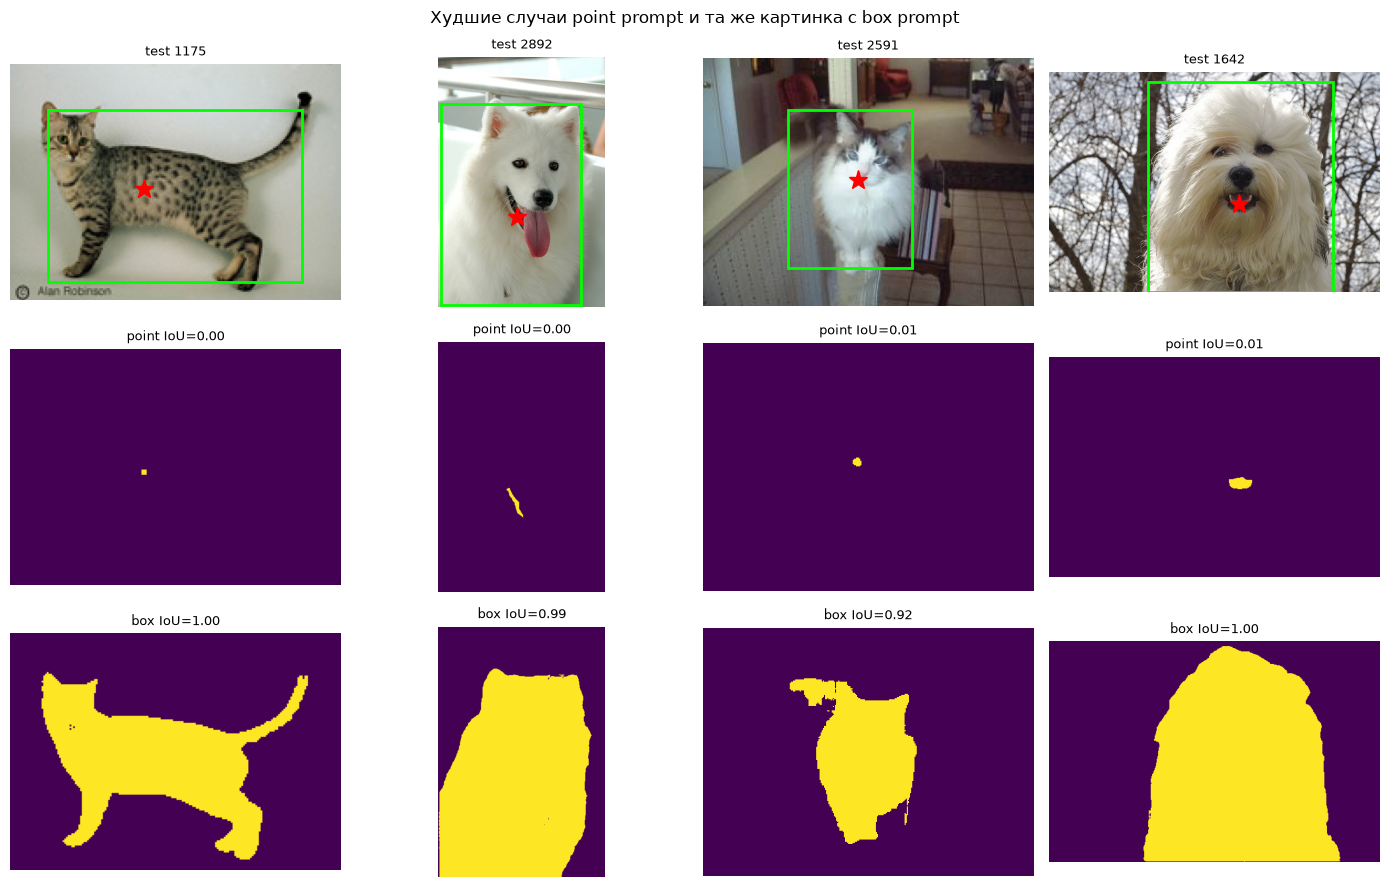

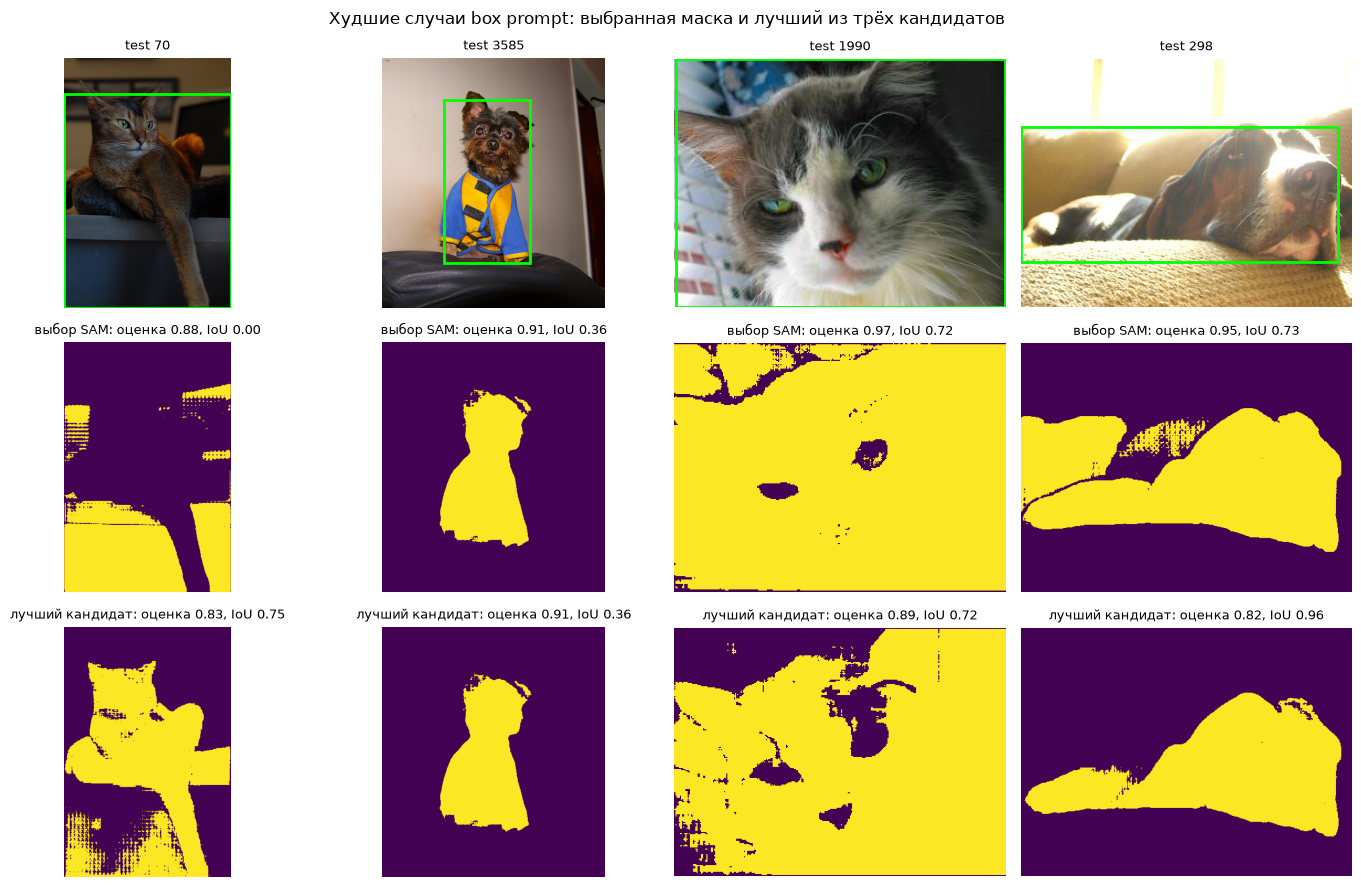

In [6]:
prompt_rows, sam_box_masks, sam_box_logits, sam_point_masks, box_candidates = [], [], [], [], []
t0 = time.time()
for k, (image, trimap) in enumerate(eval_ds):
    fg, valid, obj = gt_masks(trimap)
    cache = image_embedding(image)          # один embedding на два prompt
    pt, bx = median_point(fg), box_from_mask(fg)
    lp, sp = sam_candidates(image, point=pt, cache=cache)
    lb, sb = sam_candidates(image, box=bx, cache=cache)
    m_pt, s_pt = lp[sp.argmax()] > 0, float(sp.max())          # выбор маски — по предсказанной SAM оценке IoU
    l_bx, s_bx = lb[sb.argmax()], float(sb.max()); m_bx = l_bx > 0
    sam_point_masks.append(m_pt); sam_box_masks.append(m_bx); sam_box_logits.append(l_bx)
    box_candidates.append(lb > 0)
    prompt_rows.append({"test_index": int(eval_idx[k]), "size": list(trimap.shape), "point": pt, "box": bx,
                        "union_box_inflated": bool(inflated_union_box(trimap)),
                        "gt_area": int(fg.sum()), "point_area": int(m_pt.sum()), "box_area": int(m_bx.sum()),
                        "point_iou": iou(m_pt, fg, valid), "box_iou": iou(m_bx, fg, valid),
                        "point_pred_score": s_pt, "box_pred_score": s_bx,
                        # для анализа выбора: IoU с GT и оценка SAM у каждого из трёх кандидатов
                        "point_candidates": {"iou": [iou(l > 0, fg, valid) for l in lp], "score": sp.tolist()},
                        "box_candidates": {"iou": [iou(l > 0, fg, valid) for l in lb], "score": sb.tolist()}})
sam_time = time.time() - t0
point_iou = np.array([r["point_iou"] for r in prompt_rows]); box_iou = np.array([r["box_iou"] for r in prompt_rows])
summary = {"n": len(prompt_rows), "mean_point_iou": float(point_iou.mean()), "mean_box_iou": float(box_iou.mean()),
           "median_point_iou": float(np.median(point_iou)), "median_box_iou": float(np.median(box_iou)),
           "box_better_share": float((box_iou > point_iou).mean()), "seconds_per_image_two_prompts": sam_time / len(prompt_rows),
           "n_union_box_inflated": int(sum(r["union_box_inflated"] for r in prompt_rows))}
for kind in ("point", "box"):
    best_cand = np.array([max(r[f"{kind}_candidates"]["iou"]) for r in prompt_rows])
    chosen = np.array([r[f"{kind}_iou"] for r in prompt_rows])
    summary[f"{kind}_best_candidate_mean_iou"] = float(best_cand.mean())        # потолок при идеальном выборе кандидата
    summary[f"{kind}_selection_matches_best_share"] = float(np.mean(best_cand - chosen < 1e-6))
(ARTIFACTS / "prompt_results.json").write_text(json.dumps({"summary": summary, "rows": prompt_rows}, indent=1))
print(json.dumps(summary, indent=1))

import matplotlib.pyplot as plt
worst_pt = np.argsort(point_iou)[:4]
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for c, k in enumerate(worst_pt):
    image, trimap = eval_ds[k]; r = prompt_rows[k]
    axes[0, c].imshow(image); axes[0, c].plot(*r["point"], "r*", ms=14)
    x0, y0, x1, y1 = r["box"]; axes[0, c].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
    axes[0, c].set_title(f"test {r['test_index']}", fontsize=9)
    axes[1, c].imshow(sam_point_masks[k]); axes[1, c].set_title(f"point IoU={r['point_iou']:.2f}", fontsize=9)
    axes[2, c].imshow(sam_box_masks[k]); axes[2, c].set_title(f"box IoU={r['box_iou']:.2f}", fontsize=9)
for ax in axes.flat: ax.axis("off")
fig.suptitle("Худшие случаи point prompt и та же картинка с box prompt"); fig.tight_layout()
fig.savefig(ARTIFACTS / "prompt_examples.png", dpi=100); plt.show()

worst_bx = np.argsort(box_iou)[:4]
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for c, k in enumerate(worst_bx):
    image, trimap = eval_ds[k]; r = prompt_rows[k]; cand = r["box_candidates"]; j = int(np.argmax(cand["iou"]))
    axes[0, c].imshow(image); x0, y0, x1, y1 = r["box"]
    axes[0, c].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2)); axes[0, c].set_title(f"test {r['test_index']}", fontsize=9)
    axes[1, c].imshow(sam_box_masks[k]); axes[1, c].set_title(f"выбор SAM: оценка {r['box_pred_score']:.2f}, IoU {r['box_iou']:.2f}", fontsize=9)
    axes[2, c].imshow(box_candidates[k][j]); axes[2, c].set_title(f"лучший кандидат: оценка {cand['score'][j]:.2f}, IoU {cand['iou'][j]:.2f}", fontsize=9)
for ax in axes.flat: ax.axis("off")
fig.suptitle("Худшие случаи box prompt: выбранная маска и лучший из трёх кандидатов"); fig.tight_layout()
fig.savefig(ARTIFACTS / "box_failures.png", dpi=100); plt.show()

### Обучение supervised baseline

*Вес: 1 балл.*

**Постановка.** Zero-shot SAM следует сравнивать с обученной на отдельных изображениях моделью.

Выполните следующие действия:
1. Подготовьте бинарные маски trainval.
2. Обучите LRASPP без доступа к test и сохраните веса.

**Результат.** supervised.pt с обученными весами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
from torch.utils.data import TensorDataset, DataLoader

SUP_SIZE = 128 if FAST_DEV_RUN else 320
SUP_EPOCHS = 1 if FAST_DEV_RUN else 10
IGNORE = 255
sup_idx = np.arange(len(pets_trainval))
if FAST_DEV_RUN:
    sup_idx = sup_idx[:96]

def to_tensor_pair(image, trimap, size):
    x = torch.from_numpy(np.array(image.resize((size, size), Image.BILINEAR))).permute(2, 0, 1)
    t = np.array(Image.fromarray(trimap).resize((size, size), Image.NEAREST))
    y = np.where(t == 1, 1, np.where(t == 2, 0, IGNORE)).astype(np.uint8)   # граница не участвует в loss
    return x, torch.from_numpy(y)

pairs = [to_tensor_pair(*load_item(pets_trainval, int(i)), SUP_SIZE) for i in sup_idx]
sup_X = torch.stack([p[0] for p in pairs]); sup_Y = torch.stack([p[1] for p in pairs])
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
def prepare(x):
    return (x.to(DEVICE).float() / 255 - MEAN) / STD

torch.manual_seed(SEED)
sup_model = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1)
sup_model.classifier.low_classifier = nn.Conv2d(sup_model.classifier.low_classifier.in_channels, 2, 1)
sup_model.classifier.high_classifier = nn.Conv2d(sup_model.classifier.high_classifier.in_channels, 2, 1)
sup_model = sup_model.to(DEVICE)
sup_path = ARTIFACTS / "supervised.pt"
if sup_path.exists():
    sup_model.load_state_dict(torch.load(sup_path, map_location=DEVICE)["state_dict"]); print("загружен supervised.pt")
else:
    sup_loader = DataLoader(TensorDataset(sup_X, sup_Y), batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    opt = torch.optim.AdamW(sup_model.parameters(), lr=5e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=5e-4, total_steps=SUP_EPOCHS * len(sup_loader), pct_start=0.1)
    t0 = time.time()
    for epoch in range(SUP_EPOCHS):
        sup_model.train(); losses = []
        for x, y in sup_loader:
            x = prepare(x)
            if torch.rand(1).item() < 0.5:                      # синхронное отражение пары
                x, y = x.flip(-1), y.flip(-1)
            loss = F.cross_entropy(sup_model(x)["out"], y.to(DEVICE).long(), ignore_index=IGNORE)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); losses.append(loss.item())
        print(f"supervised эпоха {epoch + 1}/{SUP_EPOCHS}: loss {np.mean(losses):.4f}")
    torch.save({"state_dict": sup_model.state_dict(), "size": SUP_SIZE, "epochs": SUP_EPOCHS, "train_split": "trainval",
                "train_time_s": time.time() - t0}, sup_path)
print("supervised LRASPP обучен на", len(sup_idx), "изображениях trainval; test не использовался")

supervised эпоха 1/10: loss 0.1948


supervised эпоха 2/10: loss 0.0497


supervised эпоха 3/10: loss 0.0334


supervised эпоха 4/10: loss 0.0232


supervised эпоха 5/10: loss 0.0175


...

supervised эпоха 7/10: loss 0.0113


supervised эпоха 8/10: loss 0.0098


supervised эпоха 9/10: loss 0.0092


supervised эпоха 10/10: loss 0.0087


supervised LRASPP обучен на 3680 изображениях trainval; test не использовался


### Парное сравнение с baseline

*Вес: 1 балл.*

**Постановка.** Парные изображения исключают разницу в составе оценочной выборки.

Выполните следующие действия:
1. Предскажите test-маски supervised модели.
2. Сравните её IoU с SAM box на тех же индексах.

**Результат.** supervised_comparison.json с парными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
@torch.no_grad()
def predict_supervised(image):
    sup_model.eval()
    x = torch.from_numpy(np.array(image.resize((SUP_SIZE, SUP_SIZE), Image.BILINEAR))).permute(2, 0, 1)[None]
    logits = sup_model(prepare(x))["out"]
    logits = F.interpolate(logits, size=(image.height, image.width), mode="bilinear", align_corners=False)
    return logits.argmax(1)[0].cpu().numpy() == 1

sup_iou = []
for k, (image, trimap) in enumerate(eval_ds):
    fg, valid, _ = gt_masks(trimap)
    sup_iou.append(iou(predict_supervised(image), fg, valid))
sup_iou = np.array(sup_iou)
from scipy.stats import wilcoxon
stat = wilcoxon(box_iou, sup_iou)
sup_cmp = {"n": len(sup_iou), "mean_iou_sam_box": float(box_iou.mean()), "mean_iou_supervised": float(sup_iou.mean()),
           "sam_box_better_share": float((box_iou > sup_iou).mean()), "wilcoxon_p": float(stat.pvalue),
           "pairs": [{"test_index": int(i), "sam_box_iou": float(a), "supervised_iou": float(b)} for i, a, b in zip(eval_idx, box_iou, sup_iou)]}
(ARTIFACTS / "supervised_comparison.json").write_text(json.dumps(sup_cmp, indent=1))
print({k: v for k, v in sup_cmp.items() if k != "pairs"})

{'n': 200, 'mean_iou_sam_box': 0.9668710880549953, 'mean_iou_supervised': 0.9744986223151215, 'sam_box_better_share': 0.475, 'wilcoxon_p': 0.24147008531564274}


### Обучающие маски для корректора

*Вес: 1 балл.*

**Постановка.** Корректор должен обучаться только на train-изображениях и масках SAM.

Выполните следующие действия:
1. Получите SAM-предсказания для trainval.
2. Сформируйте четырёхканальные входы из RGB и маски.

**Результат.** refine_train из реальных изображений и масок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
N_REFINE = 48 if FAST_DEV_RUN else 600
HEAD_SIZE = 128 if FAST_DEV_RUN else 384
trainval_with_object = np.array([i for i in range(len(pets_trainval)) if has_object(pets_trainval, i)])
refine_idx = np.sort(np.random.RandomState(SEED + 1).choice(trainval_with_object, N_REFINE, replace=False))

def head_inputs(image, sam_logit):
    """4 канала: RGB и вероятность маски SAM, приведённые к HEAD_SIZE."""
    x = torch.from_numpy(np.array(image.resize((HEAD_SIZE, HEAD_SIZE), Image.BILINEAR))).permute(2, 0, 1).float() / 255
    l = F.interpolate(torch.from_numpy(sam_logit)[None, None].float(), size=(HEAD_SIZE, HEAD_SIZE), mode="bilinear", align_corners=False)[0]
    return torch.cat([x, torch.sigmoid(l)]), l

rx, rl, ry = [], [], []
t0 = time.time()
for i in refine_idx:
    image, trimap = load_item(pets_trainval, int(i))
    fg, valid, obj = gt_masks(trimap)
    _, _, logit = predict_sam(image, box=box_from_mask(fg), return_logits=True)
    x4, l = head_inputs(image, logit)
    t = np.array(Image.fromarray(trimap).resize((HEAD_SIZE, HEAD_SIZE), Image.NEAREST))
    rx.append(x4); rl.append(l); ry.append(torch.from_numpy(np.where(t == 1, 1, np.where(t == 2, 0, IGNORE)).astype(np.uint8)))
refine_train = TensorDataset(torch.stack(rx), torch.stack(rl), torch.stack(ry))
train_files = {Path(pets_trainval._images[int(i)]).name for i in refine_idx}
test_files = {Path(pets_test._images[int(i)]).name for i in eval_idx}
check(not (train_files & test_files) and len(refine_train) == N_REFINE, "корректор учится только на trainval-изображениях, без test")
print(f"refine_train: {len(refine_train)} примеров, вход {tuple(refine_train[0][0].shape)}; SAM по trainval занял {time.time() - t0:.0f} c")

✔ корректор учится только на trainval-изображениях, без test
refine_train: 600 примеров, вход (4, 384, 384); SAM по trainval занял 460 c


### Обучение корректирующей головы

*Вес: 1 балл.*

**Постановка.** Обучаемая свёрточная голова может уточнять ошибочную маску.

Выполните следующие действия:
1. Обучите голову на подготовленных четырёхканальных входах.
2. Сохраните веса для повторного использования.

**Результат.** refinement.pt после фактической оптимизации.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
class RefineHead(nn.Module):
    """Маленький U-Net: по RGB и маске SAM предсказывает поправку к логитам SAM (последний слой нулевой → старт с тождества)."""
    def __init__(self, ch=32):
        super().__init__()
        block = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                           nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        self.e1, self.e2, self.e3 = block(4, ch), block(ch, 2 * ch), block(2 * ch, 4 * ch)
        self.d2, self.d1 = block(6 * ch, 2 * ch), block(3 * ch, ch)
        self.out = nn.Conv2d(ch, 1, 1)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(F.max_pool2d(e1, 2)); e3 = self.e3(F.max_pool2d(e2, 2))
        d2 = self.d2(torch.cat([F.interpolate(e3, scale_factor=2), e2], 1))
        d1 = self.d1(torch.cat([F.interpolate(d2, scale_factor=2), e1], 1))
        return self.out(d1)

def refine_loss(delta, sam_logit, y):
    logit = (sam_logit + delta)[:, 0]
    valid = y != IGNORE
    target = (y == 1).float()
    bce = F.binary_cross_entropy_with_logits(logit[valid], target[valid])
    p = torch.sigmoid(logit) * valid
    dice = 1 - (2 * (p * target).sum() + 1) / (p.sum() + (target * valid).sum() + 1)
    return bce + dice

REF_EPOCHS = 2 if FAST_DEV_RUN else 25
torch.manual_seed(SEED)
head = RefineHead().to(DEVICE)
ref_loader = DataLoader(refine_train, batch_size=8, shuffle=True, generator=torch.Generator().manual_seed(SEED))
opt = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, REF_EPOCHS * len(ref_loader))
ref_hist = []
t0 = time.time()
for epoch in range(REF_EPOCHS):
    head.train(); losses = []
    for x4, l, y in ref_loader:
        x4, l, y = x4.to(DEVICE), l.to(DEVICE), y.to(DEVICE)
        if torch.rand(1).item() < 0.5:
            x4, l, y = x4.flip(-1), l.flip(-1), y.flip(-1)
        loss = refine_loss(head(x4), l, y)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); losses.append(loss.item())
    ref_hist.append(float(np.mean(losses)))
    if epoch % 5 == 0 or epoch == REF_EPOCHS - 1:
        print(f"refine эпоха {epoch + 1}/{REF_EPOCHS}: loss {ref_hist[-1]:.4f}")
torch.save({"state_dict": head.state_dict(), "head_size": HEAD_SIZE, "epochs": REF_EPOCHS, "loss_history": ref_hist,
            "train_indices": refine_idx.tolist(), "train_time_s": time.time() - t0}, ARTIFACTS / "refinement.pt")
check(ref_hist[-1] < ref_hist[0], "loss корректора уменьшился")

refine эпоха 1/25: loss 0.1118


refine эпоха 6/25: loss 0.1004


refine эпоха 11/25: loss 0.0984


refine эпоха 16/25: loss 0.0928


refine эпоха 21/25: loss 0.0902


refine эпоха 25/25: loss 0.0923
✔ loss корректора уменьшился


### Независимая оценка коррекции

*Вес: 1 балл.*

**Постановка.** Качество коррекции необходимо измерить на отложенных изображениях.

Выполните следующие действия:
1. Примените обученную голову к SAM-маскам test.
2. Сохраните IoU и долю исходных масок, требующих существенной правки.

**Результат.** adapted_comparison.json с измеренными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
@torch.no_grad()
def refine_mask(image, sam_logit):
    head.eval()
    x4, _ = head_inputs(image, sam_logit)
    delta = head(x4[None].to(DEVICE))
    delta = F.interpolate(delta, size=sam_logit.shape, mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    return (sam_logit + delta) > 0

ref_iou = []
for k, (image, trimap) in enumerate(eval_ds):
    fg, valid, _ = gt_masks(trimap)
    ref_iou.append(iou(refine_mask(image, sam_box_logits[k]), fg, valid))
ref_iou = np.array(ref_iou)
adapted = {"n": len(ref_iou), "mean_iou_sam_box": float(box_iou.mean()), "mean_iou_refined": float(ref_iou.mean()),
           "mean_iou_supervised": float(sup_iou.mean()), "refined_better_share": float((ref_iou > box_iou).mean()),
           "wilcoxon_p_refined_vs_sam": float(wilcoxon(ref_iou, box_iou).pvalue)}
for tau in (0.8, 0.9):
    adapted[f"need_major_fix_iou<{tau}"] = {"sam_point": float((point_iou < tau).mean()), "sam_box": float((box_iou < tau).mean()),
                                           "refined": float((ref_iou < tau).mean()), "supervised": float((sup_iou < tau).mean())}
(ARTIFACTS / "adapted_comparison.json").write_text(json.dumps(adapted, indent=2))
print(json.dumps(adapted, indent=1))

{
 "n": 200,
 "mean_iou_sam_box": 0.9668710880549953,
 "mean_iou_refined": 0.9695899861524996,
 "mean_iou_supervised": 0.9744986223151215,
 "refined_better_share": 0.725,
 "wilcoxon_p_refined_vs_sam": 3.279457873621847e-12,
 "need_major_fix_iou<0.8": {
  "sam_point": 0.25,
  "sam_box": 0.03,
  "refined": 0.035,
  "supervised": 0.02
 },
 "need_major_fix_iou<0.9": {
  "sam_point": 0.325,
  "sam_box": 0.09,
  "refined": 0.09,
  "supervised": 0.055
 }
}


### Сопоставление трудных случаев

*Вес: 1 балл.*

**Постановка.** Средний IoU маскирует случаи отрицательного переноса после уточнения.

Выполните следующие действия:
1. Соедините SAM, supervised и corrected IoU по test-индексам.
2. Укажите изображения, где корректор снизил IoU по сравнению с SAM.

**Результат.** correction_failures.json с реальными индексами и тремя IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


корректор ухудшил 36 из 200 масок; худшие:
{'test_index': 184, 'sam_box_iou': 0.9087151377640993, 'supervised_iou': 0.9683843359261818, 'corrected_iou': 0.8757258870705051, 'delta': -0.03298925069359415}
{'test_index': 1396, 'sam_box_iou': 0.9929852320675105, 'supervised_iou': 0.9727663640707119, 'corrected_iou': 0.9774525829635972, 'delta': -0.015532649103913387}
{'test_index': 1106, 'sam_box_iou': 0.8683821814506725, 'supervised_iou': 0.9917905824039653, 'corrected_iou': 0.8531835497162403, 'delta': -0.015198631734432144}
{'test_index': 817, 'sam_box_iou': 0.9562003947423676, 'supervised_iou': 0.9997201192292083, 'corrected_iou': 0.9426503730455353, 'delta': -0.013550021696832282}
{'test_index': 2611, 'sam_box_iou': 0.966142392519565, 'supervised_iou': 0.986820138827871, 'corrected_iou': 0.9541493037910357, 'delta': -0.011993088728529333}


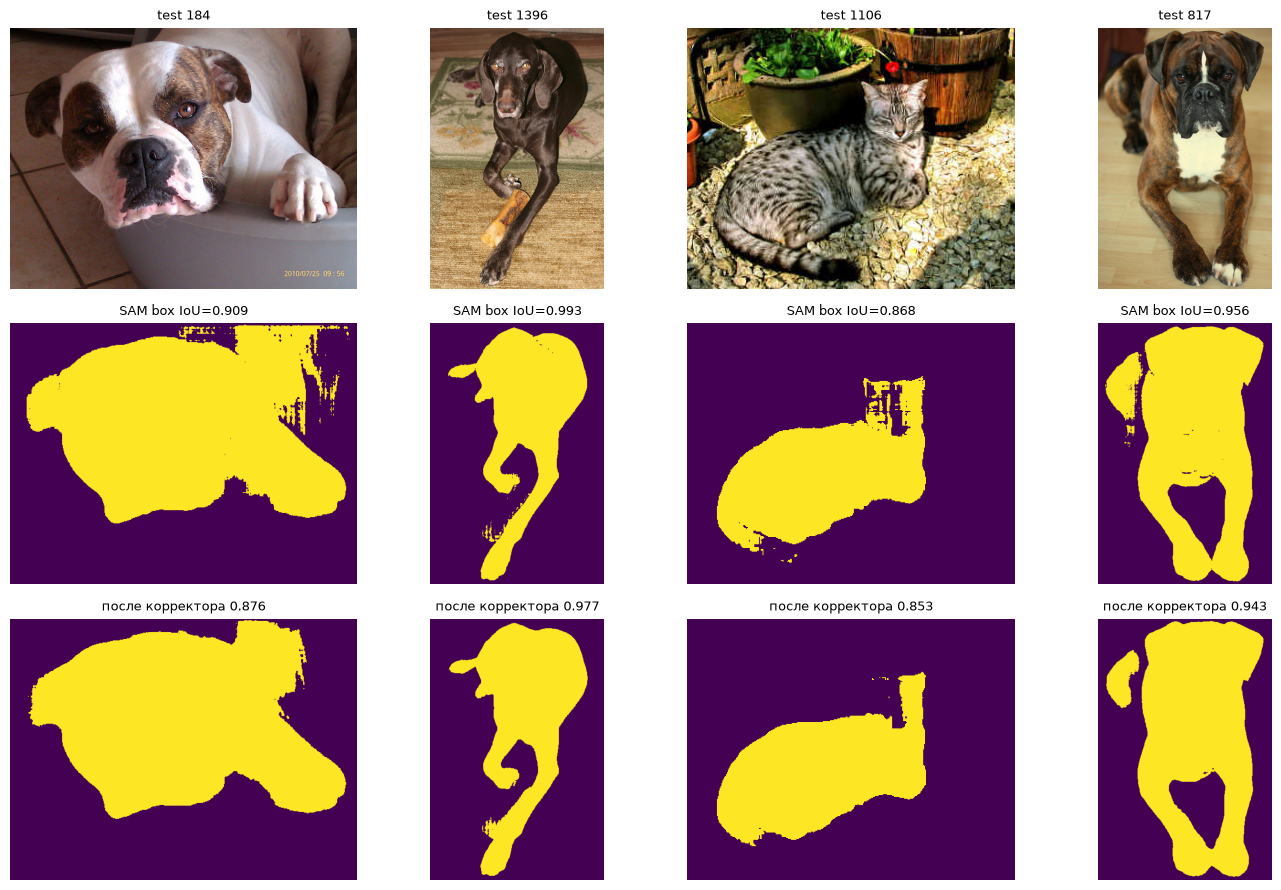

In [12]:
joined = [{"test_index": int(i), "sam_box_iou": float(a), "supervised_iou": float(b), "corrected_iou": float(c), "delta": float(c - a)}
          for i, a, b, c in zip(eval_idx, box_iou, sup_iou, ref_iou)]
worse = sorted([r for r in joined if r["corrected_iou"] < r["sam_box_iou"]], key=lambda r: r["delta"])
(ARTIFACTS / "correction_failures.json").write_text(json.dumps({"n": len(joined), "n_worse_after_correction": len(worse),
    "n_better_after_correction": sum(r["corrected_iou"] > r["sam_box_iou"] for r in joined), "worse": worse, "all": joined}, indent=1))
print(f"корректор ухудшил {len(worse)} из {len(joined)} масок; худшие:")
for r in worse[:5]: print(r)
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for c, r in enumerate(worse[:4]):
    k = int(np.where(eval_idx == r["test_index"])[0][0]); image, trimap = eval_ds[k]
    axes[0, c].imshow(image); axes[0, c].set_title(f"test {r['test_index']}", fontsize=9)
    axes[1, c].imshow(sam_box_masks[k]); axes[1, c].set_title(f"SAM box IoU={r['sam_box_iou']:.3f}", fontsize=9)
    axes[2, c].imshow(refine_mask(image, sam_box_logits[k])); axes[2, c].set_title(f"после корректора {r['corrected_iou']:.3f}", fontsize=9)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ARTIFACTS / "correction_failures.png", dpi=100); plt.show()

### Творческий бонус: второй тип точки

*Вес: 1 дополнительный балл.*

**Постановка.** Качество SAM зависит от выбора положительной точки.

Выполните следующие действия:
1. Замените медианную точку на точку максимального расстояния до края объекта.
2. На тех же test-изображениях сравните IoU с исходной подсказкой.

**Результат.** bonus_points.json с парными IoU для двух стратегий.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [13]:
from scipy.ndimage import distance_transform_edt

def interior_point(mask):
    """Точка объекта с максимальным расстоянием до его края."""
    dist = distance_transform_edt(mask)
    y, x = np.unravel_index(np.argmax(dist), dist.shape)
    return [int(x), int(y)]

bonus_rows = []
for k, (image, trimap) in enumerate(eval_ds):
    fg, valid, _ = gt_masks(trimap)
    m_in, _ = predict_sam(image, point=interior_point(fg))
    bonus_rows.append({"test_index": int(eval_idx[k]), "median_point": prompt_rows[k]["point"], "interior_point": interior_point(fg),
                       "median_point_iou": prompt_rows[k]["point_iou"], "interior_point_iou": iou(m_in, fg, valid)})
a = np.array([r["median_point_iou"] for r in bonus_rows]); b = np.array([r["interior_point_iou"] for r in bonus_rows])
bonus = {"n": len(bonus_rows), "mean_median_point_iou": float(a.mean()), "mean_interior_point_iou": float(b.mean()),
         "interior_better_share": float((b > a).mean()), "wilcoxon_p": float(wilcoxon(a, b).pvalue), "rows": bonus_rows}
(ARTIFACTS / "bonus_points.json").write_text(json.dumps(bonus, indent=1))
print({k: v for k, v in bonus.items() if k != "rows"})

{'n': 200, 'mean_median_point_iou': 0.8148691140915719, 'mean_interior_point_iou': 0.8000346770853852, 'interior_better_share': 0.455, 'wilcoxon_p': 0.8848864674844238}


## Анализ результатов

**Данные и бюджет.** Oxford-IIIT Pet (CC BY-SA 4.0). Оценка — на 200 изображениях official test (seed 42), выбранных из 3 662 изображений с размеченным животным; 7 test-trimap без класса «животное» исключены. Длинная сторона уменьшена до 512 px. GT — класс 1 trimap. Полоса неопределённости (класс 3) в IoU не учитывается — так принято для Pets, и это одинаково завышает IoU всех методов. Подсказки строятся по GT и имитируют действия разметчика: точка — пиксель животного, ближайший к покоординатной медиане, рамка — bbox класса 1. SAM ViT-B (93,7 M параметров) заморожен: один image embedding на изображение и по 3 кандидата маски на каждую подсказку, 0,77 с на изображение с двумя подсказками (GPU делили другие задачи). Supervised baseline — LRASPP MobileNetV3: 10 эпох на всех 3 680 изображениях trainval, 320 px. Корректор — маленький U-Net по RGB и вероятности SAM: 600 изображений trainval, 25 эпох, 384 px. Test не используется ни в одном обучении — это проверяется в ноутбуке.

**Находка в разметке.** В первой версии рамка строилась по объединению классов 1 и 3. В 22 из 200 изображений класс 3 размечен ещё и вдоль краёв кадра, и такая рамка охватывала весь кадр. SAM выделял по ней фон с IoU около 0, средний IoU рамок был 0,936. Разметчик такую рамку не нарисовал бы, поэтому рамка строится по классу 1. На этих 22 изображениях IoU теперь в среднем 0,99.

**Точка против рамки** (200 изображений):

| подсказка | mean IoU | median IoU | IoU < 0,8 | IoU < 0,5 | выбор SAM = лучший кандидат | mean IoU лучшего кандидата |
|---|---:|---:|---:|---:|---:|---:|
| точка | 0,815 | 0,989 | 25 % | 16 % (32) | 62,5 % | 0,958 |
| рамка | **0,967** | 0,994 | 3 % | 1 % (2) | 84 % | 0,978 |

Распределение IoU для точки бимодально: медиана 0,99, но 16 % масок почти пустые. В 26 из 32 провалов маска меньше 30 % животного: пятно на шерсти, язык, нос (`prompt_examples.png`). Это неоднозначность «часть или целое» у одного клика, и SAM её не теряет: среди трёх кандидатов в 25 из 32 провалов есть маска с IoU ≥ 0,8. Ошибается выбор по предсказанной SAM оценке IoU: у test 2892 и 1642 кандидат с IoU 0,99 получил оценку 0,70–0,73, а выбран фрагмент с оценкой 0,79–0,92. При идеальном выборе кандидата средний IoU точки вырос бы с 0,815 до 0,958. Как фильтр оценка SAM слабая: корреляция Спирмена с реальным IoU — 0,50 для точки и 0,31 для рамки, средняя оценка на провалах 0,89 против 0,97 на удачных масках.

**Худшие случаи рамки** (`box_failures.png`):
1. test 70 — SAM выбрал ящик под кошкой (оценка 0,88, IoU 0,00). Кандидат с кошкой (IoU 0,75) получил 0,83.
2. test 298 — собака на диване: выбранная маска захватила подушку (IoU 0,73), второй кандидат даёт 0,96.
3. test 3585 — собака в костюме: все кандидаты включают одежду, а в GT животное — только голова и лапы. IoU 0,36 — расхождение определения объекта, а не ошибка сегментации.
4. test 1990 — морда кошки на весь кадр: рамка совпадает с кадром, и маска затекает в окно за кошкой (IoU 0,72).

**SAM против supervised** (те же 200 изображений): LRASPP — 0,974, SAM с рамкой — 0,967. Медиана парной разности ≈ 0, критерий Уилкоксона p = 0,24, SAM лучше на 47,5 % изображений. Различия значимо не обнаружено. Ошибаются модели по-разному. Supervised проваливается на нетипичных снимках (test 3283: 0,39 против 0,99 у SAM; 3319: 0,52 против 1,00), SAM — на выборе кандидата и спорном определении объекта. Разница в стоимости: SAM нужна рамка на каждое изображение (человек или детектор), supervised-модель работает автоматически, но потребовала 3 680 размеченных масок.

**Корректор** (адаптация по 600 примерам trainval): mean IoU 0,967 → 0,970. Улучшено 145 масок из 200, ухудшено 36; p = 3·10⁻¹² — прирост устойчивый, но маленький (+0,003). Сильнее всего выигрывают маски с шумом и протечками: test 410 — 0,909 → 0,991, test 2012 — 0,911 → 0,983. Ухудшения не больше 0,033 и приходятся на тонкие структуры — уши, лапы, шерсть по контуру (test 184, 817, 1106, `correction_failures.png`). Голова работает в 384 px, а её поправка интерполируется в исходный размер, поэтому мелкие детали сглаживаются. Доля масок, требующих существенной правки, не меняется: IoU < 0,8 — 3 % → 3,5 %, IoU < 0,9 — 9 % → 9 %. Грубые ошибки (не тот кандидат, другое определение объекта) корректор не исправляет.

**Бонус: точка в глубине объекта.** Точка с максимальным расстоянием до края (distance transform) вместо медианной: mean IoU 0,800 против 0,815, лучше на 45,5 % изображений, p = 0,88 — разницы нет. Провалов с IoU < 0,5 — 37 против 32: новая точка исправляет 15, ломает 20, на 17 изображениях проваливаются обе. Точки отстоят друг от друга в среднем на 39 px. Положение клика не снимает неоднозначность «часть или целое»: в глубине тела тоже лежат пятна шерсти и детали, которые SAM считает отдельной частью.

**Ограничения.** Подсказки из GT — верхняя оценка для автоматического детектора. 200 test-изображений, IoU без полосы границы, один seed. Обучение корректора на MPS недетерминировано: два запуска дали 0,9701 и 0,9696. Время измерено при параллельной нагрузке на GPU.

## Выводы

1. SAM с рамкой по GT сегментирует питомцев с IoU 0,967 без обучения на этом домене — на уровне LRASPP, обученного на 3 680 масках (0,974, разница незначима).
2. Одна точка ненадёжна (IoU < 0,5 в 16 % случаев), но причина в выборе маски, а не в сегментации: лучший из трёх кандидатов в среднем даёт 0,958. Рамка оставляет 2 провала вместо 32, а при правильном выборе кандидата исправимы 25 из 32 провалов точки.
3. Корректор, обученный на 600 масках, стабильно, но мало улучшает рамочные маски (+0,003, улучшено 145 из 200) и не уменьшает долю грубых ошибок.
4. Рамка по trimap «животное + граница» ломается на 11 % изображений (22 из 200) из-за полосы границы у краёв кадра: при построении подсказок из разметки её нужно проверять.